# Fixed-rate stability: explore the admissible parameter region

This is a standalone design notebook for the Kirchhoff–Carrier string. It does not import the simulator,
run a waveform, or use SymPy. The base sampling rate is **44,100 Hz**.
Oversampling is fixed at **1×**, so the time step is 1/44,100 s.

Start with **128 spatial intervals**. Edit the numeric controls and press Enter or leave a field:
the diagnostics and plot update without rerunning cells. Values outside the bound stay visible so that you can
see why they fail. A live Python kernel with `ipywidgets` is required; a static initial view is saved below for readers.
In VS Code, select the project’s Pixi Python environment and Run All after `pixi install`.

**Scope:** “within the bound” means the linear grid condition encoded in Russo’s implementation, with its 1% spacing margin.
It does **not** certify nonlinear amplitude stability, floating-point safety for arbitrary magnitudes, realistic materials,
or useful gradients. We investigate numerical admissibility, not sound quality.

You can change the number of intervals while exploring, but freeze it for an actual optimisation run.
More intervals mean a finer grid, more computation, and a tighter bound at a given time step.
An even interval count puts a point at the string midpoint; require at least four intervals.

Source: [Russo’s MATLAB implementation](https://github.com/Nemus-Project/nLinStringsConv-SAV/blob/5253d5c8dc7e2645c925fd45f57f6bc32b66f2ec/KCstring/KCStringSAV_noSplit.m)
(`h`, `N`, and `k` calculations); its undamped counterpart appears as Eq. (71) in
[Russo, Ducceschi & Bilbao (2026)](https://doi.org/10.1007/s11071-026-12708-0).


## The shared stability allowance

The grid spacing is $h=L/N$. To retain the reference's 1% spacing margin, evaluate the limiting formula at
$H=h/1.01$. The actual grid is slightly coarser than this effective spacing.
With $\mu=\rho\pi r^2$, $c^2=T_0/\mu$, and $K^2=Er^2/(4\rho)$, the condition is
$$S=\underbrace{\frac{T_0\Delta t^2}{\rho\pi r^2H^2}}_{\text{tension contribution }a}
+\underbrace{\frac{Er^2\Delta t^2}{\rho H^4}}_{\text{bending contribution }b}
+\underbrace{\frac{4\sigma_1\Delta t}{H^2}}_{\text{damping contribution }d}\leq1.$$
All three terms are dimensionless. They share the allowance: increasing one leaves less room for the others.
Halving $h$ multiplies the tension and damping terms by four, and the bending term by sixteen.

For this implementation require $\rho,r,E,L>0$ and $T_0,\sigma_0,\sigma_1\geq0$.
$E=0$ is excluded because the existing dispersion-calibration formula divides by stiffness squared.
The initial amplitude may be any finite signed input here, but **this linear bound does not certify that amplitude**.
$\sigma_0$ does not enter this bound; its nonnegativity ensures a positive effective mass in the rank-one solve.

The damping coefficients are independent controls. Their initial values reproduce the reference's two-point
calibration, including its $6\ln(10)$ convention. They are not recalibrated to fixed decay-time targets as other controls change.

## Conditional limits are not a box of joint ranges

The table answers: “how far can this **one** parameter move if the others and the displayed working rate remain fixed?”
The plot answers: “which combinations of **two** parameters work when everything else is fixed?”
Neither allows combining all individual maxima independently.

For example, holding the others fixed gives
$$T_{0,\max}=\frac{\rho\pi r^2H^2}{\Delta t^2}(1-b-d),\qquad
E_{\max}=\frac{\rho H^4}{r^2\Delta t^2}(1-a-d),$$
$$\sigma_{1,\max}=\frac{H^2}{4\Delta t}(1-a-b),\qquad
\rho_{\min}=\rho\frac{a+b}{1-d}\quad(d<1).$$
A negative upper bound means no admissible nonnegative value; a nonpositive modulus upper bound means
no admissible positive modulus. If $d\geq1$, changing density alone cannot help.

Radius affects tension and bending in opposite directions. With $y=(r_{\mathrm{new}}/r)^2$, solve
$$b y^2-(1-d)y+a\leq0.$$
The nonnegative discriminant and positive roots determine the interval for radius. If there are no such roots,
there is no feasible radius with the other values fixed. This is why radius generally has both a minimum and a maximum.

Length must satisfy $L\geq N(1.01)h_{\min}$, where
$$h_{\min}=\sqrt{\frac{c^2\Delta t^2+4\sigma_1\Delta t+
\sqrt{(c^2\Delta t^2+4\sigma_1\Delta t)^2+16K^2\Delta t^2}}{2}}.$$
Conversely, $N_{\max}$ is the largest even integer whose grid meets this bound. The code verifies that candidate
against $S\leq1$ to handle rounding at the boundary.


## A fixed optimisation configuration

Here $\Delta t=1/44100$ throughout. Changing a parameter can move the model outside the bound, but the notebook
never increases oversampling or clips your input to hide that failure.
The plot shows the joint feasible region for the chosen axes; all other values remain at the controls' current values.
The black contour, when present, is $S=1$. Grey points violate the basic input domain or cannot be assessed numerically.

At the reference parameters, 128 intervals give $S\approx0.595$, while 256 intervals give $S\approx7.089$.
Thus 128 is a useful starting point for exploring headroom at this rate; it is not a universal best grid or an accuracy claim.
Use the automatic-oversampling notebook if you want to see the cost of accommodating a configuration outside this region.


## Calculation and widget definitions

These two code cells contain all the implementation. They are collapsed initially so you can start with the controls. Expand them to inspect the algebra or interface code.

In [1]:
import math
import html

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import ipywidgets as widgets
from IPython.display import HTML, display, clear_output

base_sample_rate = 44_100
spacing_margin = 1.01

# Native units are SI. The last column converts a displayed input to SI.
parameter_info = {
    'density': ('Density', 'kg/m³', 1.0),
    'tension': ('Tension', 'N', 1.0),
    'radius': ('Radius', 'mm', 1e-3),
    'modulus': ("Young's modulus", 'GPa', 1e9),
    'length': ('Length', 'm', 1.0),
    'amplitude': ('Initial amplitude', 'mm', 1e-3),
    'sigma_0': ('Uniform damping σ₀', '1/s', 1.0),
    'sigma_1': ('Frequency-dependent damping σ₁', 'm²/s', 1.0),
}
positive_parameters = ('density', 'radius', 'modulus', 'length')
nonnegative_parameters = ('tension', 'sigma_0', 'sigma_1')
plot_parameters = ('tension', 'modulus', 'radius', 'density', 'length', 'sigma_1')

# Reproduce the reference's initial damping calibration once. The controls then
# treat sigma_0 and sigma_1 as independent parameters, not as fixed T60 targets.
default_density = 8050.0
default_radius = 3.5560e-4
default_modulus = 174e9
default_c_squared = 75 / (default_density * math.pi * default_radius**2)
default_K_squared = default_modulus * default_radius**2 / (4 * default_density)
default_z_2 = (-default_c_squared + math.sqrt(
    default_c_squared**2 + 4 * default_K_squared * (2 * math.pi * 1000)**2
)) / (2 * default_K_squared)
default_parameters = {
    'density': default_density, 'tension': 75.0, 'radius': default_radius,
    'modulus': default_modulus, 'length': 1.0, 'amplitude': 0.002,
    'sigma_0': 6 * math.log(10) / 15,
    'sigma_1': (6 * math.log(10) / 10 - 6 * math.log(10) / 15) / default_z_2,
}


def validate_inputs(parameters, intervals):
    errors = []
    if not isinstance(intervals, (int, np.integer)) or intervals < 4 or intervals % 2:
        errors.append('N must be an even integer of at least 4 intervals.')
    for key, (label, unit, _) in parameter_info.items():
        value = parameters[key]
        if not math.isfinite(value):
            errors.append(f'{label} must be finite.')
        elif key in positive_parameters and value <= 0:
            errors.append(f'{label} must be strictly positive.')
        elif key in nonnegative_parameters and value < 0:
            errors.append(f'{label} must be nonnegative.')
    return errors


def coefficients(parameters, intervals):
    """Return coefficients A and B in S = A*dt² + B*dt, plus useful geometry."""
    density = parameters['density']
    radius = parameters['radius']
    spacing = parameters['length'] / intervals
    effective_spacing = spacing / spacing_margin
    mass_per_length = density * math.pi * radius**2
    c_squared = parameters['tension'] / mass_per_length
    K_squared = parameters['modulus'] * radius**2 / (4 * density)
    tension_coefficient = c_squared / effective_spacing**2
    bending_coefficient = 4 * K_squared / effective_spacing**4
    damping_coefficient = 4 * parameters['sigma_1'] / effective_spacing**2
    values = (mass_per_length, effective_spacing, K_squared, bending_coefficient)
    if not all(math.isfinite(x) and x > 0 for x in values):
        raise ArithmeticError('Geometry or stiffness exceeds the supported floating-point range.')
    if not all(math.isfinite(x) for x in (tension_coefficient, damping_coefficient)):
        raise ArithmeticError('The stability coefficients exceed the supported floating-point range.')
    return {
        'spacing': spacing, 'H': effective_spacing, 'mass_per_length': mass_per_length,
        'c_squared': c_squared, 'K_squared': K_squared,
        'tension_coefficient': tension_coefficient,
        'bending_coefficient': bending_coefficient,
        'A': tension_coefficient + bending_coefficient, 'B': damping_coefficient,
    }


def score_parts(coeff, sample_rate):
    dt = 1 / sample_rate
    return {
        'Tension': coeff['tension_coefficient'] * dt * dt,
        'Bending': coeff['bending_coefficient'] * dt * dt,
        'Damping σ₁': coeff['B'] * dt,
    }


def required_sample_rate(coeff):
    # Positive root of A*dt² + B*dt = 1, written without subtractive cancellation.
    return coeff['B'] / 2 + math.hypot(coeff['B'] / 2, math.sqrt(coeff['A']))


def minimum_spacing(coeff, sigma_1, sample_rate):
    dt = 1 / sample_rate
    wave_and_loss = coeff['c_squared'] * dt * dt + 4 * sigma_1 * dt
    return math.sqrt(wave_and_loss / 2 + math.hypot(
        wave_and_loss / 2, 2 * math.sqrt(coeff['K_squared']) * dt
    ))


def maximum_intervals(parameters, coeff, sample_rate):
    spacing_limit = spacing_margin * minimum_spacing(coeff, parameters['sigma_1'], sample_rate)
    raw_limit = parameters['length'] / spacing_limit
    if not math.isfinite(raw_limit):
        raise ArithmeticError('The interval limit exceeds the supported floating-point range.')
    largest_even = 2 * math.floor(raw_limit / 2)
    # Verify the final candidate in the same arithmetic used for the displayed score.
    if largest_even >= 4:
        candidate = coefficients(parameters, largest_even)
        if sum(score_parts(candidate, sample_rate).values()) > 1:
            largest_even -= 2
    return largest_even if largest_even >= 4 else None


def evaluate(parameters, intervals=128, adaptive=False):
    errors = validate_inputs(parameters, intervals)
    if errors:
        return {'valid': False, 'errors': errors}
    try:
        coeff = coefficients(parameters, intervals)
        minimum_rate = required_sample_rate(coeff)
        if not math.isfinite(minimum_rate) or minimum_rate <= 0:
            raise ArithmeticError('No representable positive rate could be calculated.')
        factor = 1
        if adaptive:
            factor = 2 ** max(0, math.ceil(math.log2(minimum_rate / base_sample_rate)))
            while sum(score_parts(coeff, base_sample_rate * factor).values()) > 1:
                factor *= 2
            while factor > 1 and sum(score_parts(coeff, base_sample_rate * (factor // 2)).values()) <= 1:
                factor //= 2
        sample_rate = float(base_sample_rate * factor)
        if not math.isfinite(sample_rate):
            raise ArithmeticError('The required rate exceeds the supported floating-point range.')
        parts = score_parts(coeff, sample_rate)
        score = sum(parts.values())
        return {
            'valid': True, 'errors': [], 'coeff': coeff, 'factor': factor,
            'sample_rate': sample_rate, 'time_step': 1 / sample_rate,
            'minimum_rate': minimum_rate, 'parts': parts, 'score': score,
            'base_score': sum(score_parts(coeff, base_sample_rate).values()),
            'passes': score <= 1, 'remaining': 1 - score,
            'maximum_intervals': maximum_intervals(parameters, coeff, sample_rate),
        }
    except (ArithmeticError, ValueError, OverflowError, ZeroDivisionError) as error:
        return {'valid': False, 'errors': [f'Cannot assess these values numerically: {error}']}


def conditional_ranges(parameters, result, intervals):
    """Analytic ranges with every other parameter AND the displayed rate fixed.

    Each item is (lower, upper, lower_is_open). None means no admissible value.
    These are not independent bounds for simultaneous optimisation.
    """
    if not result['valid']:
        return {}
    tension_part, bending_part, loss_part = result['parts'].values()
    coeff = result['coeff']
    H = coeff['H']
    dt = result['time_step']
    density = parameters['density']
    radius = parameters['radius']
    # The coefficients stay nonzero even when current tension or sigma_1 is zero.
    tension_upper = (1 - bending_part - loss_part) * coeff['mass_per_length'] * (H / dt)**2
    modulus_upper = (1 - tension_part - loss_part) * density * H**4 / (radius**2 * dt**2)
    loss_upper = (1 - tension_part - bending_part) * H**2 / (4 * dt)
    density_lower = (density * (tension_part + bending_part) / (1 - loss_part)
                     if loss_part < 1 else None)
    length_lower = intervals * spacing_margin * minimum_spacing(
        coeff, parameters['sigma_1'], result['sample_rate']
    )
    ranges = {
        'tension': (0., tension_upper, False) if tension_upper >= 0 else None,
        'modulus': (0., modulus_upper, True) if modulus_upper > 0 else None,
        'sigma_1': (0., loss_upper, False) if loss_upper >= 0 else None,
        'density': (density_lower, math.inf, False) if density_lower is not None else None,
        'length': (length_lower, math.inf, False),
        'sigma_0': (0., math.inf, False),
        'amplitude': (-math.inf, math.inf, False),
    }
    # y = (new_radius / current_radius)^2:
    # bending_part*y² - (1-loss_part)*y + tension_part <= 0.
    allowance = 1 - loss_part
    discriminant = allowance**2 - 4 * bending_part * tension_part
    ranges['radius'] = None
    if allowance > 0 and discriminant >= 0:
        root_sum = allowance + math.sqrt(discriminant)
        lower_y = 2 * tension_part / root_sum
        upper_y = root_sum / (2 * bending_part)
        ranges['radius'] = (radius * math.sqrt(lower_y), radius * math.sqrt(upper_y), lower_y == 0)
    return ranges


def format_number(value):
    if value == math.inf:
        return '∞'
    if value == -math.inf:
        return '−∞'
    return f'{value:.6g}'


def diagnostic_html(parameters, intervals, result, adaptive=False):
    if not result['valid']:
        messages = ''.join(f'<li>{html.escape(message)}</li>' for message in result['errors'])
        return f'<h3 style="color:#a12020">Invalid input / not assessable</h3><ul>{messages}</ul><p>Your inputs have been preserved.</p>'
    color = '#12715c' if result['passes'] else '#a12020'
    status = 'Within the linear bound' if result['passes'] else 'Outside the linear bound'
    text = f'<h3 style="color:{color}">{status}: S = {result["score"]:.6g} (limit 1)</h3>'
    text += f'<p>Remaining allowance: <b>{result["remaining"]:.6g}</b>. '
    text += f'N = {intervals}; h = {result["coeff"]["spacing"]:.6g} m; '
    text += f'Δt = {result["time_step"]:.6g} s.</p>'
    text += '<p>' + ' + '.join(f'{name}: {value:.6g}' for name, value in result['parts'].items()) + '</p>'
    text += f'<p>Working rate: <b>{result["sample_rate"]:,.6g} Hz</b>; oversampling: <b>{result["factor"]}×</b>. '
    text += f'Minimum rate from this bound: {result["minimum_rate"]:,.6g} Hz.</p>'
    maximum = result['maximum_intervals']
    text += f'<p>Largest admissible even N at this working rate: <b>{maximum if maximum is not None else "none ≥ 4"}</b>.</p>'
    if adaptive:
        text += f'<p>At 1×, S = <b>{result["base_score"]:.6g}</b>. The adviser selects the smallest sufficient power of two. '
        text += 'This is a design calculation, not a changing time step inside a simulation.</p>'
    if not result['passes']:
        text += '<p>The three contributions exceed the shared allowance. Reduce one or more contributions, '
        text += 'reduce N, or increase length. No parameter has been clipped.</p>'
    text += '<h4>Conditional limits at the displayed working rate</h4><p>Each row holds all other current values fixed. '
    text += '<b>Do not combine all row maxima as an independent parameter box.</b></p>'
    if adaptive:
        text += '<p>These limits hold the selected oversampling factor fixed; the adviser can select a different factor after your next edit.</p>'
    text += '<table><tr><th>Parameter</th><th>Admissible range</th><th>Interpretation</th></tr>'
    for key, (label, unit, scale) in parameter_info.items():
        limits = conditional_ranges(parameters, result, intervals).get(key)
        if key == 'amplitude':
            value = 'No amplitude bound established'
        elif limits is None:
            value = 'No admissible value with the others fixed'
        else:
            lower, upper, lower_open = limits
            value = f'{"(" if lower_open or not math.isfinite(lower) else "["}{format_number(lower / scale)}, '
            value += f'{format_number(upper / scale)}{")" if not math.isfinite(upper) else "]"} {unit}'
        note = ('Not certified by this linear bound' if key == 'amplitude' else
                'No upper limit from this bound' if key == 'sigma_0' else 'Others held fixed')
        text += f'<tr><td>{html.escape(label)}</td><td>{value}</td><td>{note}</td></tr>'
    text += '</table><p>[ ] includes an endpoint; ( ) excludes it. ∞ means no limit from this formula, '
    text += 'not unlimited floating-point capacity. Passing this test is not a guarantee of nonlinear, gradient, or physical validity.</p>'
    return text


In [2]:
def region_values(parameters, intervals, x_key, y_key, x_limits, y_limits, adaptive=False, points=101):
    """Evaluate a joint slice of parameter space. Plot coordinates use display units."""
    if x_key == y_key:
        raise ValueError('Choose two different parameters for the joint plot.')
    if any(not math.isfinite(v) for v in (*x_limits, *y_limits)):
        raise ValueError('Plot limits must be finite.')
    if x_limits[0] >= x_limits[1] or y_limits[0] >= y_limits[1]:
        raise ValueError('Each plot minimum must be smaller than its maximum.')
    x = np.linspace(*x_limits, points)
    y = np.linspace(*y_limits, points)
    X, Y = np.meshgrid(x, y)
    p = {key: np.full_like(X, value) for key, value in parameters.items()}
    p[x_key] = X * parameter_info[x_key][2]
    p[y_key] = Y * parameter_info[y_key][2]
    valid = np.ones_like(X, dtype=bool)
    for key in positive_parameters:
        valid &= np.isfinite(p[key]) & (p[key] > 0)
    for key in nonnegative_parameters:
        valid &= np.isfinite(p[key]) & (p[key] >= 0)
    with np.errstate(over='ignore', invalid='ignore', divide='ignore', under='ignore'):
        H = p['length'] / (intervals * spacing_margin)
        A = (p['tension'] / (p['density'] * np.pi * p['radius']**2 * H**2)
             + p['modulus'] * p['radius']**2 / (p['density'] * H**4))
        B = 4 * p['sigma_1'] / H**2
        valid &= np.isfinite(A) & np.isfinite(B) & (A > 0)
        score = A / base_sample_rate / base_sample_rate + B / base_sample_rate
        if adaptive:
            minimum_rate = B / 2 + np.hypot(B / 2, np.sqrt(A))
            exponent = np.maximum(0, np.ceil(np.log2(minimum_rate / base_sample_rate)))
            working_rate = base_sample_rate * np.exp2(exponent)
            chosen_score = A / working_rate / working_rate + B / working_rate
            exponent = np.where(chosen_score > 1, exponent + 1, exponent)
            valid &= np.isfinite(exponent) & np.isfinite(base_sample_rate * np.exp2(exponent))
            values = np.where(valid, exponent, np.nan)
        else:
            valid &= np.isfinite(score)
            values = np.where(valid, np.where(score <= 1, 1, 0), np.nan)
    return X, Y, values, np.where(valid, score, np.nan)


def region_figure(parameters, intervals, x_key='tension', y_key='modulus',
                  x_limits=(0., 400.), y_limits=(0., 500.), adaptive=False):
    X, Y, values, scores = region_values(parameters, intervals, x_key, y_key, x_limits, y_limits, adaptive)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.set_facecolor('#d9d9d9')
    finite_values = values[np.isfinite(values)]
    if adaptive and finite_values.size:
        smallest = int(np.min(finite_values))
        largest = int(np.max(finite_values))
        boundaries = np.arange(smallest - 0.5, largest + 1.5)
        cmap = plt.get_cmap('viridis', largest - smallest + 1).copy()
        cmap.set_bad('#d9d9d9')
        image = ax.pcolormesh(X, Y, np.ma.masked_invalid(values), cmap=cmap,
                             norm=BoundaryNorm(boundaries, cmap.N), shading='auto')
        tick_step = max(1, math.ceil((largest - smallest + 1) / 8))
        ticks = list(range(smallest, largest + 1, tick_step))
        if largest not in ticks:
            ticks.append(largest)
        colorbar = fig.colorbar(image, ax=ax, ticks=ticks)
        colorbar.set_ticklabels([f'{2**n}×' if n < 16 else f'2^{n}×' for n in ticks])
        colorbar.set_label('Smallest sufficient oversampling factor')
        ax.set_title('Required oversampling across a joint parameter slice')
        legend = [Patch(facecolor='#d9d9d9', label='Invalid / not numerically assessable')]
    else:
        cmap = ListedColormap(['#edaaa6', '#83c8b5'])
        cmap.set_bad('#d9d9d9')
        ax.pcolormesh(X, Y, np.ma.masked_invalid(values), cmap=cmap, vmin=0, vmax=1, shading='auto')
        ax.set_title('Joint admissible region at 44,100 Hz, 1×')
        legend = [Patch(facecolor='#83c8b5', label='Within linear bound'),
                  Patch(facecolor='#edaaa6', label='Outside linear bound'),
                  Patch(facecolor='#d9d9d9', label='Invalid / not assessable')]
        if adaptive:
            ax.set_title('No numerically assessable points in this plot window')
    finite_scores = scores[np.isfinite(scores)]
    if finite_scores.size and np.min(finite_scores) < 1 < np.max(finite_scores):
        ax.contour(X, Y, scores, levels=[1], colors=['#333333'], linewidths=1)
    current_x = parameters[x_key] / parameter_info[x_key][2]
    current_y = parameters[y_key] / parameter_info[y_key][2]
    if x_limits[0] <= current_x <= x_limits[1] and y_limits[0] <= current_y <= y_limits[1]:
        ax.plot(current_x, current_y, 'o', color='white', markeredgecolor='black', label='Current parameters')
    else:
        ax.text(0.02, 0.98, 'Current parameters are outside this plot window', transform=ax.transAxes,
                va='top', bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none'})
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles=legend + handles, loc='upper right', fontsize=8)
    ax.set(xlabel=f'{parameter_info[x_key][0]} ({parameter_info[x_key][1]})',
           ylabel=f'{parameter_info[y_key][0]} ({parameter_info[y_key][1]})',
           xlim=x_limits, ylim=y_limits)
    fig.tight_layout()
    return fig


class StabilityExplorer:
    """Numeric edits refresh diagnostics and the joint plot without rerunning cells."""
    def __init__(self, adaptive=False):
        self.adaptive = adaptive
        self.updating = False
        self.controls = {}
        style = {'description_width': '250px'}
        for key, (label, unit, scale) in parameter_info.items():
            label = {'sigma_0': 'Uniform damping σ₀', 'sigma_1': 'Damping σ₁'}.get(key, label)
            self.controls[key] = widgets.FloatText(
                value=default_parameters[key] / scale, description=f'{label} ({unit})',
                style=style, layout=widgets.Layout(width='430px'),
            )
        self.intervals = widgets.IntText(value=128, description='Spatial intervals N', style=style,
                                        layout=widgets.Layout(width='430px'))
        options = [(parameter_info[key][0], key) for key in plot_parameters]
        self.x_axis = widgets.Dropdown(options=options, value='tension', description='Horizontal axis')
        self.y_axis = widgets.Dropdown(options=options, value='modulus', description='Vertical axis')
        self.x_min = widgets.FloatText(value=0, description='X minimum')
        self.x_max = widgets.FloatText(value=400, description='X maximum')
        self.y_min = widgets.FloatText(value=0, description='Y minimum')
        self.y_max = widgets.FloatText(value=500, description='Y maximum')
        self.report = widgets.HTML()
        self.plot_output = widgets.Output()
        self.plot_message = widgets.HTML()
        self.reset_button = widgets.Button(description='Reset reference values', icon='refresh')
        self.reset_button.on_click(self.reset)
        fixed_text = ('Base rate: 44,100 Hz. Oversampling is selected automatically.' if adaptive else
                      'Base rate: 44,100 Hz. Oversampling: 1× (fixed).')
        self.widget = widgets.VBox([
            widgets.HTML(f'<b>{fixed_text}</b><p>Edit a numeric field and press Enter or leave the field. '
                         'The view updates automatically. No simulation is run and inputs are never clipped.</p>'),
            widgets.GridBox(list(self.controls.values()) + [self.intervals],
                            layout=widgets.Layout(grid_template_columns='repeat(auto-fit, minmax(440px, 1fr))')),
            self.reset_button, self.report,
            widgets.HTML('<h4>Joint parameter slice</h4><p>Plot limits use the units named on the axes. '
                         'They control the view, not admissible parameter ranges. Changing an axis resets only its view limits.</p>'),
            widgets.HBox([self.x_axis, self.y_axis]),
            widgets.HBox([self.x_min, self.x_max]), widgets.HBox([self.y_min, self.y_max]),
            self.plot_message, self.plot_output,
        ])
        for control in [*self.controls.values(), self.intervals, self.x_min, self.x_max, self.y_min, self.y_max]:
            control.observe(self.refresh, names='value')
        self.x_axis.observe(self.axis_changed, names='value')
        self.y_axis.observe(self.axis_changed, names='value')
        self.refresh()

    def parameters(self):
        return {key: control.value * parameter_info[key][2] for key, control in self.controls.items()}

    def reset(self, _=None):
        self.updating = True
        try:
            for key, control in self.controls.items():
                control.value = default_parameters[key] / parameter_info[key][2]
            self.intervals.value = 128
            self.x_axis.value, self.y_axis.value = 'tension', 'modulus'
            self.x_min.value, self.x_max.value = 0, 400
            self.y_min.value, self.y_max.value = 0, 500
        finally:
            self.updating = False
        self.refresh()

    def axis_changed(self, change):
        if self.updating:
            return
        key = change['new']
        value = abs(self.controls[key].value)
        if not math.isfinite(value) or value == 0:
            value = default_parameters[key] / parameter_info[key][2]
        minimum = value / 10 if key in positive_parameters else 0
        maximum = 3 * value
        if not math.isfinite(maximum):
            minimum, maximum = 0, 1
        self.updating = True
        try:
            if change['owner'] is self.x_axis:
                self.x_min.value, self.x_max.value = minimum, maximum
            else:
                self.y_min.value, self.y_max.value = minimum, maximum
        finally:
            self.updating = False
        self.refresh()

    def refresh(self, _=None):
        if self.updating:
            return
        parameters = self.parameters()
        self.last_result = evaluate(parameters, self.intervals.value, self.adaptive)
        try:
            self.report.value = diagnostic_html(parameters, self.intervals.value, self.last_result, self.adaptive)
        except (ArithmeticError, ValueError) as error:
            self.report.value = f'<p>Conditional limits cannot be represented for these extreme values: {html.escape(str(error))}</p>'
        self.last_plot_error = None
        self.plot_message.value = ''
        with self.plot_output:
            clear_output(wait=True)
            if not self.last_result['valid']:
                display(HTML('<p>Correct the invalid inputs above to evaluate a joint slice.</p>'))
                return
            try:
                figure = region_figure(parameters, self.intervals.value, self.x_axis.value, self.y_axis.value,
                                       (self.x_min.value, self.x_max.value), (self.y_min.value, self.y_max.value),
                                       self.adaptive)
                display(figure)
                plt.close(figure)
            except (ArithmeticError, ValueError) as error:
                self.last_plot_error = str(error)
                self.plot_message.value = f'<p style="color:#a12020">Plot: {html.escape(str(error))}</p>'
                display(HTML('<p>The numerical diagnostics above remain available.</p>'))


In [3]:
# Independent known cases, rather than checking only the displayed defaults.
expected_scores = {64: 0.07503150021249279, 128: 0.5945588968817995, 256: 7.089161924036451}
for intervals, expected in expected_scores.items():
    actual = evaluate(default_parameters, intervals, adaptive=False)
    assert actual['valid'] and math.isclose(actual['score'], expected, rel_tol=1e-12)
for intervals, expected_factor in ((128, 1), (256, 4), (512, 16)):
    chosen = evaluate(default_parameters, intervals, adaptive=True)
    assert chosen['factor'] == expected_factor and chosen['passes']
    if expected_factor > 1:
        assert sum(score_parts(chosen['coeff'], base_sample_rate * (expected_factor // 2)).values()) > 1
print('Default scores and minimal power-of-two factors verified.')

Default scores and minimal power-of-two factors verified.


## Live explorer

The controls below are the interactive view. If only a widget placeholder appears, select a running Pixi kernel and Run All; the saved snapshot further down remains readable without widgets.

In [4]:
explorer = StabilityExplorer(adaptive=False)
display(explorer.widget)

## Saved reference view

This initial snapshot is static and intentionally does not follow subsequent control edits. Use the live view above for current values.

Parameter,Admissible range,Interpretation
Density,"[4784.78, ∞) kg/m³",Others held fixed
Tension,"[0, 225.873] N",Others held fixed
Radius,"[0.167086, 0.542262] mm",Others held fixed
Young's modulus,"(0, 353.702] GPa",Others held fixed
Length,"[0.857693, ∞) m",Others held fixed
Initial amplitude,No amplitude bound established,Not certified by this linear bound
Uniform damping σ₀,"[0, ∞) 1/s",No upper limit from this bound
Frequency-dependent damping σ₁,"[0, 0.267737] m²/s",Others held fixed


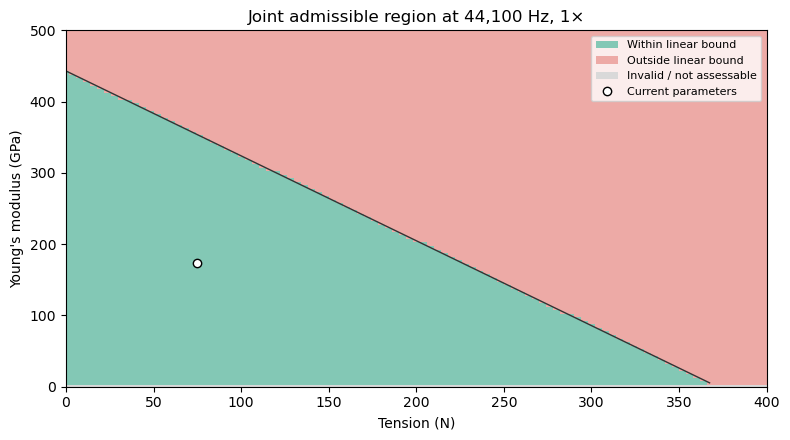

In [5]:
initial_result = evaluate(default_parameters, 128, adaptive=False)
display(HTML(diagnostic_html(default_parameters, 128, initial_result, adaptive=False)))
initial_figure = region_figure(default_parameters, 128, adaptive=False)
display(initial_figure)
plt.close(initial_figure)

## What to carry into an optimisation run

Choose and freeze the base rate, oversampling factor, and interval count. Enforce the coupled constraint rather than treating the conditional table as independent bounds. Nonlinear amplitude limits and gradient conditioning need separate analysis. No waveform accuracy or full nonlinear stability claim is made here.